# 03 — Image-Only CNN Baseline (PathVQA)

**Capstone:** Question-Type-Aware Multimodal Fusion for Pathology Visual Question Answering (QTAF-Net)

## Objective
Train a **CNN from scratch using pathology images only**, without feeding question text into the model. Compare it with the Question-Only BiLSTM and CNN + BiLSTM baselines.

**Controlled protocol**
- Use the same cleaned PathVQA training and validation splits.
- Use the original **1,000-class open-ended answer vocabulary** from `late_fusion_latest.pth`; **no weights** are transferred.
- Reuse the original 224 × 224 image preprocessing and four-block CNN architecture.
- Use two heads (yes/no and open-ended), with **oracle answer-type routing**: ground-truth answer type selects the output head during validation. **Answer type is not given to the CNN as an input feature.**
- All trainable weights start randomly initialized; **no pretrained weights, backbones, embeddings, or external features**.
- Training: Adam lr=0.001, weight decay=1e-5, batch=32, max 30 epochs, patience 5.
- Fine-tuning: reload **best original weights**, new Adam lr=0.0001, max 10 additional epochs, patience 3.
- Validation chooses checkpoints; test set remains untouched.

**Important interpretation:** An image-only model cannot identify the specific question about an image. This experiment measures what it can predict from visual features plus the *evaluation-time* answer-type selection, not genuine image-conditioned question answering.


### Submission guide: execution and reproducibility

**Purpose.** This notebook evaluates how well pathology images alone can predict PathVQA answers, without reading the question. It is a diagnostic baseline for the multimodal models.

**Environment.** Run in Kaggle with Internet enabled for the initial Hugging Face dataset download and a GPU accelerator if available. The first code cell installs `datasets` and imports the required Python libraries, including PyTorch, torchvision, Pillow, pandas, NumPy, Matplotlib, and scikit-learn. Kaggle usually provides these packages, but package versions may differ between sessions.

**Required input.** Attach the dataset containing `late_fusion_latest.pth` from Notebook 01. This file supplies the **same top-1,000 open-answer mapping** used by the late-fusion experiment; it is not used to initialize the image-only CNN weights. The code searches Kaggle input and working directories for it. The PathVQA dataset is loaded from `flaviagiammarino/path-vqa`.

**Run order.** Execute the notebook from top to bottom: load data → remove train/validation image overlaps → load answer mapping → preprocess images → create dataloaders → define the model and loss → train and validate → restore the best checkpoint → fine-tune → evaluate and plot → save artifacts. Checkpoint-restoration sections require the relevant earlier checkpoint to exist, either from a preceding cell or an attached Kaggle dataset.

**Evaluation interpretation.** The image-only model does not receive question text, but its two answer heads are selected using the ground-truth yes/no versus open answer type during validation (**oracle routing**). It is therefore an image-only diagnostic control with answer-type information supplied at evaluation, not a standalone deployable image-only predictor. Test-set evaluation is intentionally deferred to the shared final evaluation notebook.

**Reproducibility caveat.** Running from a fresh Kaggle session depends on external dataset access, the shared answer-mapping checkpoint, and package/GPU availability. The saved training outputs document the original run; this annotated copy has not been re-executed. No model or training logic has been changed.


## 1. Kaggle setup

Create a new Kaggle notebook called `03_Image_Only_CNN.ipynb`. Enable GPU (T4 recommended), add your original **1,000-answer** `late_fusion_latest.pth` checkpoint as a Kaggle Input, and enable Internet for the dataset download if needed.

The previous checkpoint is used **only for answer-label mapping**, not for model weights. You may run this notebook from the top. When reopening after training, skip the training/fine-tuning loops and restore the saved weights.

In [5]:
# Install the dataset loader and import libraries; set seeds and choose CPU/GPU.
!pip -q install datasets

import os, glob, hashlib, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Torch:", torch.__version__)

Device: cuda
Torch: 2.11.0+cu130


## 2. Load PathVQA

Expected dataset sizes: train 19,654; validation 6,259; test 6,719. We will **not evaluate on the test set** until final model selection is complete.

In [7]:
# Load PathVQA splits; keep the held-out test split for the shared final evaluation.
dataset = load_dataset("flaviagiammarino/path-vqa")
for split in ("train", "validation", "test"):
    print(split, len(dataset[split]))
print("Columns:", dataset["train"].column_names)

train 19654
validation 6259
test 6719
Columns: ['image', 'question', 'answer']


## 3. Remove image overlap between training and validation

To match your previous baselines, hash RGB image pixels and dimensions. The original run removed six training question-answer pairs associated with a validation image. Images are used normally in this image-only model, but no questions are supplied as model inputs.

**Why this matters:** identical image content appearing in both splits could inflate validation performance. Only training records are removed; validation is unchanged.

In [8]:
# Hash RGB pixels and image dimensions to detect identical images across train and validation.
def image_hash(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

validation_hashes = {
    image_hash(sample["image"])
    for sample in tqdm(dataset["validation"], desc="Hash validation images")
}
keep_indices = [
    i for i, sample in enumerate(tqdm(dataset["train"], desc="Check train overlap"))
    if image_hash(sample["image"]) not in validation_hashes
]
clean_train = dataset["train"].select(keep_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]

print("Original train:", len(dataset["train"]))
print("Clean train:", len(clean_train))
print("Removed:", len(dataset["train"]) - len(clean_train))
print("Validation:", len(clean_val))
assert len(clean_train) == 19648, "Dataset cleaning differs from previous experiment; inspect before comparing."

Hash validation images:   0%|          | 0/6259 [00:00<?, ?it/s]

Check train overlap:   0%|          | 0/19654 [00:00<?, ?it/s]

Original train: 19654
Clean train: 19648
Removed: 6
Validation: 6259


## 4. Restore the original 1,000-answer mapping

We reuse `open_answer2idx` from your original CNN + BiLSTM checkpoint to ensure that output class indices are identical. **No neural-network weights are loaded.**

In [9]:
# Find Notebook 01’s checkpoint and reuse its training-derived answer-to-index mapping.
candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
for i, path in enumerate(candidates):
    print(i, path)
if not candidates:
    raise FileNotFoundError("Add the original late_fusion_latest.pth as Kaggle Input.")
if len(candidates) > 1:
    raise RuntimeError("More than one checkpoint found. Choose the correct original 1K checkpoint manually.")

# Only load checkpoints that you created/trust.
original_checkpoint = torch.load(candidates[0], map_location="cpu", weights_only=False)
open_answer2idx = original_checkpoint["open_answer2idx"]
del original_checkpoint

assert len(open_answer2idx) == 1000, "Expected the original 1,000-class answer vocabulary."
print("Open answer vocabulary size:", len(open_answer2idx))

0 /kaggle/input/datasets/dollarpaisa/cnn-bilstam/late_fusion_latest.pth
Open answer vocabulary size: 1000


## 5. Encode answers and inspect coverage

`no → 0`, `yes → 1`; open answers use the original 1,000-class mapping. Open answers absent from that mapping receive label `-1`, are excluded from open cross-entropy, and count as **wrong** in validation.

The previous validation coverage was approximately 66.56%.

In [10]:
# Map binary answers to two classes and open answers to the fixed 1,000-class space.
def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no":
        return 0, 0
    if answer == "yes":
        return 0, 1
    return 1, open_answer2idx.get(answer, -1)

total_open, covered_open = 0, 0
for answer in clean_val["answer"]:
    kind, label = encode_answer(answer)
    if kind == 1:
        total_open += 1
        covered_open += int(label >= 0)

print("Validation open-ended examples:", total_open)
print("Open answers covered:", covered_open)
print(f"Coverage: {covered_open / total_open:.2%}")

Validation open-ended examples: 3134
Open answers covered: 2086
Coverage: 66.56%


## 6. Image preprocessing — exactly as the CNN + BiLSTM baseline

Convert to RGB, resize while preserving aspect ratio to fit within **224 × 224**, white-pad to 224 × 224, and convert pixels to float32 in `[0, 1]`. **No pretrained ImageNet normalization** is applied.

In [11]:
# Resize without stretching and pad to a white 224×224 image canvas.
IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")
    image = ImageOps.contain(
        image, (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR
    )
    background = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    x = (IMAGE_SIZE - image.width) // 2
    y = (IMAGE_SIZE - image.height) // 2
    background.paste(image, (x, y))
    array = np.asarray(background, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)

sample_tensor = preprocess_image(clean_train[0]["image"])
print("Shape:", sample_tensor.shape)
print("Min/Max:", sample_tensor.min().item(), sample_tensor.max().item())
assert tuple(sample_tensor.shape) == (3, 224, 224)

Shape: torch.Size([3, 224, 224])
Min/Max: 0.007843137718737125 1.0


## 7. Image-only Dataset and DataLoaders

Each batch contains only `image`, `answer_type`, and `answer_label`. The question string is **not loaded into model input**.

Use batch size 32 and **2 DataLoader workers**, as in your earlier experiments.

In [12]:
# Create image-only batches; question text is deliberately omitted.
class ImageOnlyPathVQADataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        example = self.data[index]
        answer_type, answer_label = encode_answer(example["answer"])
        return {
            "image": preprocess_image(example["image"]),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long)
        }

train_dataset = ImageOnlyPathVQADataset(clean_train)
val_dataset = ImageOnlyPathVQADataset(clean_val)

BATCH_SIZE = 32
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

batch = next(iter(train_loader))
print("Train/val examples:", len(train_dataset), len(val_dataset))
print("Train/val batches:", len(train_loader), len(val_loader))
for name, tensor in batch.items():
    print(name, tuple(tensor.shape))
assert "question" not in batch

Train/val examples: 19648 6259
Train/val batches: 614 196
image (32, 3, 224, 224)
answer_type (32,)
answer_label (32,)


## 8. Image-Only CNN architecture — trained from scratch

Use the **same image encoder** as the original late-fusion model:

`RGB image → Conv(32) → Conv(64) → Conv(128) → Conv(256) → adaptive pooling → 256 features`

Then `Linear(256,256) → ReLU → Dropout(0.3)` and separate yes/no and 1,000-class open heads.

The projection is smaller than the late-fusion model because no 256-dimensional question vector is concatenated. This is a controlled **image-only** variant, not an identical-parameter-count ablation.

In [13]:
# Define the scratch-trained convolutional encoder and separate closed/open answer heads.
class ImageEncoder(nn.Module):
    def __init__(self, feature_dim=256):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.fc = nn.Linear(256, feature_dim)

    def forward(self, images):
        features = self.cnn(images).flatten(1)
        return self.fc(features)

class ImageOnlyCNN(nn.Module):
    def __init__(self, num_open_answers=1000):
        super().__init__()
        self.image_encoder = ImageEncoder(feature_dim=256)
        self.fusion = nn.Sequential(
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.yes_no_head = nn.Linear(256, 2)
        self.open_head = nn.Linear(256, num_open_answers)

    def forward(self, images):
        features = self.image_encoder(images)
        shared = self.fusion(features)
        return self.yes_no_head(shared), self.open_head(shared)

model = ImageOnlyCNN(num_open_answers=len(open_answer2idx)).to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ImageOnlyCNN(
  (image_encoder): ImageEncoder(
    (cnn): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU()
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU()
      (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): BatchNorm2d(256, ep

## 9. Loss function

Cross-entropy is calculated separately for yes/no and **covered** open answers. If both types occur in a batch, average the two losses equally, matching the prior baselines. `-1` open answers do not contribute to training loss.

**Why this matters:** yes/no and open-ended questions have different answer spaces. Uncovered open answers are excluded from the open-head loss rather than assigned an incorrect class.

In [14]:
# Compute cross-entropy only for examples with valid target classes in each head.
def compute_loss(yes_no_logits, open_logits, answer_types, answer_labels):
    closed_mask = answer_types == 0
    open_mask = (answer_types == 1) & (answer_labels >= 0)
    losses = []
    if closed_mask.any():
        losses.append(F.cross_entropy(
            yes_no_logits[closed_mask], answer_labels[closed_mask]
        ))
    if open_mask.any():
        losses.append(F.cross_entropy(
            open_logits[open_mask], answer_labels[open_mask]
        ))
    if not losses:
        return (yes_no_logits.sum() + open_logits.sum()) * 0
    return sum(losses) / len(losses)

model.train()
with torch.no_grad():
    y_logits, o_logits = model(batch["image"].to(device))
print("Yes/no logits:", tuple(y_logits.shape))
print("Open logits:", tuple(o_logits.shape))

Yes/no logits: (32, 2)
Open logits: (32, 1000)


## 10. Training and validation functions

Gradient clipping: 1.0. Validation counts all examples and marks open answers outside the 1,000-class vocabulary incorrect.

**Oracle answer-type routing:** the validation code uses the true answer type to decide which head's prediction to score. No question text enters the model.

In [15]:
# Train with backpropagation and measure validation exact-match by answer type.
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss, total_samples = 0.0, 0
    for batch in tqdm(loader, desc="Training"):
        images = batch["image"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        optimizer.zero_grad()
        yes_no_logits, open_logits = model(images)
        loss = compute_loss(yes_no_logits, open_logits, types, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_size = images.shape[0]
        total_loss += loss.item() * batch_size
        total_samples += batch_size
    return total_loss / total_samples

@torch.no_grad()
def validate(model, loader, device):
    model.eval()
    closed_correct = closed_total = 0
    open_correct = open_total = 0
    for batch in tqdm(loader, desc="Validation"):
        images = batch["image"].to(device, non_blocking=True)
        types = batch["answer_type"].to(device)
        labels = batch["answer_label"].to(device)
        yes_no_logits, open_logits = model(images)
        closed_mask = types == 0
        open_mask = types == 1
        closed_correct += ((yes_no_logits.argmax(1) == labels) & closed_mask).sum().item()
        open_correct += ((open_logits.argmax(1) == labels) & open_mask).sum().item()
        closed_total += closed_mask.sum().item()
        open_total += open_mask.sum().item()
    total = closed_total + open_total
    return {
        "overall_accuracy": (closed_correct + open_correct) / max(total, 1),
        "closed_accuracy": closed_correct / max(closed_total, 1),
        "open_accuracy": open_correct / max(open_total, 1),
    }
print("Training and validation functions ready.")

Training and validation functions ready.


## 11. Original image-only training — up to 30 epochs

Adam (`lr=0.001`, `weight_decay=1e-5`), patience 5. Select the best checkpoint by **overall validation accuracy**. Save unique filenames so previous baseline results are not overwritten.

**Skip this cell if the original image-only model is already trained.**

In [16]:
# Run original training; save the best validation checkpoint and stop early on plateaus.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
MAX_EPOCHS = 30
PATIENCE = 5
best_accuracy = -1.0
best_epoch = 0
no_improvement = 0
history = []

best_path = "/kaggle/working/best_image_only_cnn.pth"
latest_path = "/kaggle/working/image_only_cnn_latest.pth"
history_path = "/kaggle/working/image_only_cnn_history.csv"

for epoch in range(1, MAX_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    history.append({
        "epoch": epoch, "train_loss": loss,
        "overall_accuracy": overall,
        "yes_no_accuracy": metrics["closed_accuracy"],
        "open_accuracy": metrics["open_accuracy"]
    })
    print(
        f"Epoch {epoch:02d} | Loss: {loss:.4f} | Overall: {overall:.2%} | "
        f"Yes/No: {metrics['closed_accuracy']:.2%} | "
        f"Open: {metrics['open_accuracy']:.2%}"
    )
    if overall > best_accuracy:
        best_accuracy = overall
        best_epoch = epoch
        no_improvement = 0
        torch.save(model.state_dict(), best_path)
        print("New best model saved!")
    else:
        no_improvement += 1

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "best_accuracy": best_accuracy,
        "best_epoch": best_epoch,
        "open_answer2idx": open_answer2idx,
        "model_name": "ImageOnlyCNN"
    }, latest_path)
    pd.DataFrame(history).to_csv(history_path, index=False)
    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("Best original epoch:", best_epoch)
print(f"Best original validation accuracy: {best_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 01 | Loss: 3.0979 | Overall: 27.90% | Yes/No: 51.97% | Open: 3.89%
New best model saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (66 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _Multi

Epoch 15 | Loss: 2.3929 | Overall: 31.83% | Yes/No: 53.98% | Open: 9.73%
Early stopping triggered.
Best original epoch: 10
Best original validation accuracy: 32.11%


## 12. Restore and evaluate the best original image-only model

This works after training or after adding the saved `best_image_only_cnn.pth` to Kaggle Inputs. It is also safe to use before fine-tuning.

In [17]:
# Restore the best original weights before reporting original validation results.
original_candidates = (
    glob.glob("/kaggle/working/best_image_only_cnn.pth")
    + glob.glob("/kaggle/input/**/best_image_only_cnn.pth", recursive=True)
)
if not original_candidates:
    raise FileNotFoundError("Train the original model or add best_image_only_cnn.pth as a Kaggle Input.")
original_best_checkpoint = original_candidates[0]
model.load_state_dict(
    torch.load(original_best_checkpoint, map_location=device, weights_only=True)
)
original_metrics = validate(model, val_loader, device)
print("BEST ORIGINAL IMAGE-ONLY CNN")
print(f"Overall: {original_metrics['overall_accuracy']:.2%}")
print(f"Yes/No: {original_metrics['closed_accuracy']:.2%}")
print(f"Open: {original_metrics['open_accuracy']:.2%}")
print("Checkpoint:", original_best_checkpoint)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>    
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/pyt

BEST ORIGINAL IMAGE-ONLY CNN
Overall: 32.11%
Yes/No: 54.53%
Open: 9.76%
Checkpoint: /kaggle/working/best_image_only_cnn.pth


## 13. Fine-tune from the best original checkpoint

**Fine-tuning here means continuing training your own model from its best checkpoint**, with a lower learning rate. It does **not** use any external pretrained weights.

Use the same protocol as your CNN + BiLSTM and Question-Only BiLSTM:
- Start from the best original image-only weights, not the last epoch.
- Create a **new Adam optimizer**, `lr=0.0001`, `weight_decay=1e-5`.
- Train up to 10 additional epochs, patience 3.
- Select the best fine-tuned checkpoint by overall validation accuracy.
- Save fine-tuning files separately; **never overwrite** the original best checkpoint.

**Skip this cell if the fine-tuned model is already trained.**

**Fine-tuning does not mean transfer learning here:** the same scratch-trained network is continued from its own best original weights.

In [18]:
# Continue training from the best original checkpoint using a smaller learning rate.
# Restore the original BEST weights before fine-tuning.
model.load_state_dict(
    torch.load(original_best_checkpoint, map_location=device, weights_only=True)
)
optimizer_finetune = torch.optim.Adam(
    model.parameters(), lr=0.0001, weight_decay=1e-5
)

FINETUNE_EPOCHS = 10
FINETUNE_PATIENCE = 3
best_finetune_accuracy = -1.0   # Accuracy is a fraction, NOT 48.20 or 52.95.
best_finetune_epoch = 0
no_finetune_improvement = 0
finetune_history = []

finetuned_best_path = "/kaggle/working/best_image_only_cnn_finetuned.pth"
finetuned_latest_path = "/kaggle/working/image_only_cnn_finetune_latest.pth"
finetune_history_path = "/kaggle/working/image_only_cnn_finetune_history.csv"

for epoch in range(1, FINETUNE_EPOCHS + 1):
    loss = train_one_epoch(model, train_loader, optimizer_finetune, device)
    metrics = validate(model, val_loader, device)
    overall = metrics["overall_accuracy"]
    finetune_history.append({
        "finetune_epoch": epoch,
        "train_loss": loss,
        "overall_accuracy": overall,
        "yes_no_accuracy": metrics["closed_accuracy"],
        "open_accuracy": metrics["open_accuracy"],
    })
    print(
        f"Fine-tune epoch {epoch:02d} | Loss: {loss:.4f} | "
        f"Overall: {overall:.2%} | Yes/No: {metrics['closed_accuracy']:.2%} | "
        f"Open: {metrics['open_accuracy']:.2%}"
    )
    if overall > best_finetune_accuracy:
        best_finetune_accuracy = overall
        best_finetune_epoch = epoch
        no_finetune_improvement = 0
        torch.save(model.state_dict(), finetuned_best_path)
        print("New best fine-tuned model saved!")
    else:
        no_finetune_improvement += 1

    torch.save({
        "finetune_epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer_finetune.state_dict(),
        "history": finetune_history,
        "best_accuracy": best_finetune_accuracy,
        "best_epoch": best_finetune_epoch,
        "open_answer2idx": open_answer2idx,
        "model_name": "ImageOnlyCNN_FineTuned",
        "initial_checkpoint": original_best_checkpoint,
    }, finetuned_latest_path)
    pd.DataFrame(finetune_history).to_csv(finetune_history_path, index=False)

    if no_finetune_improvement >= FINETUNE_PATIENCE:
        print("Fine-tuning early stopping triggered.")
        break

print("Best additional fine-tuning epoch:", best_finetune_epoch)
print(f"Best fine-tuned validation accuracy: {best_finetune_accuracy:.2%}")

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Fine-tune epoch 01 | Loss: 2.4761 | Overall: 31.89% | Yes/No: 54.72% | Open: 9.13%
New best fine-tuned model saved!


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (40 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a8501dca840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 10 | Loss: 2.3675 | Overall: 32.08% | Yes/No: 54.46% | Open: 9.76%
Best additional fine-tuning epoch: 9
Best fine-tuned validation accuracy: 32.21%


## 14. Restore and evaluate best fine-tuned checkpoint

Load the best saved fine-tuned weights (not the last epoch), then compare with the best original image-only result.

In [19]:
# Load the best fine-tuned checkpoint rather than the final epoch.
finetuned_candidates = (
    glob.glob("/kaggle/working/best_image_only_cnn_finetuned.pth")
    + glob.glob("/kaggle/input/**/best_image_only_cnn_finetuned.pth", recursive=True)
)
if not finetuned_candidates:
    raise FileNotFoundError(
        "Run fine-tuning or upload best_image_only_cnn_finetuned.pth as Kaggle Input."
    )
model.load_state_dict(
    torch.load(finetuned_candidates[0], map_location=device, weights_only=True)
)
finetuned_metrics = validate(model, val_loader, device)
print("BEST IMAGE-ONLY CNN AFTER FINE-TUNING")
print(f"Overall accuracy: {finetuned_metrics['overall_accuracy']:.2%}")
print(f"Yes/No accuracy: {finetuned_metrics['closed_accuracy']:.2%}")
print(f"Open-ended accuracy: {finetuned_metrics['open_accuracy']:.2%}")
print("Checkpoint:", finetuned_candidates[0])

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST IMAGE-ONLY CNN AFTER FINE-TUNING
Overall accuracy: 32.21%
Yes/No accuracy: 54.69%
Open-ended accuracy: 9.80%
Checkpoint: /kaggle/working/best_image_only_cnn_finetuned.pth


## 15. Compare original vs fine-tuned image-only CNN

Use the validation scores obtained from the checkpoints. Keep **both** versions for your report. The highest overall validation accuracy is the image-only baseline winner.

In [20]:
# Summarize original versus fine-tuned validation metrics.
image_only_comparison = pd.DataFrame([
    {
        "Model": "Image-Only CNN (original)",
        "Overall (%)": 100 * original_metrics["overall_accuracy"],
        "Yes/No (%)": 100 * original_metrics["closed_accuracy"],
        "Open (%)": 100 * original_metrics["open_accuracy"],
    },
    {
        "Model": "Image-Only CNN (fine-tuned)",
        "Overall (%)": 100 * finetuned_metrics["overall_accuracy"],
        "Yes/No (%)": 100 * finetuned_metrics["closed_accuracy"],
        "Open (%)": 100 * finetuned_metrics["open_accuracy"],
    },
])
display(image_only_comparison.round(2))
image_only_comparison.to_csv(
    "/kaggle/working/image_only_cnn_comparison.csv", index=False
)

,Model,Overall (%),Yes/No (%),Open (%)
0,Image-Only CNN (original),32.11,54.53,9.76
1,Image-Only CNN (fine-tuned),32.21,54.69,9.80


## 16. Plot original training and fine-tuning curves

Plot original and fine-tuning histories independently, since the second stage starts from the **best original checkpoint** rather than the final original epoch.

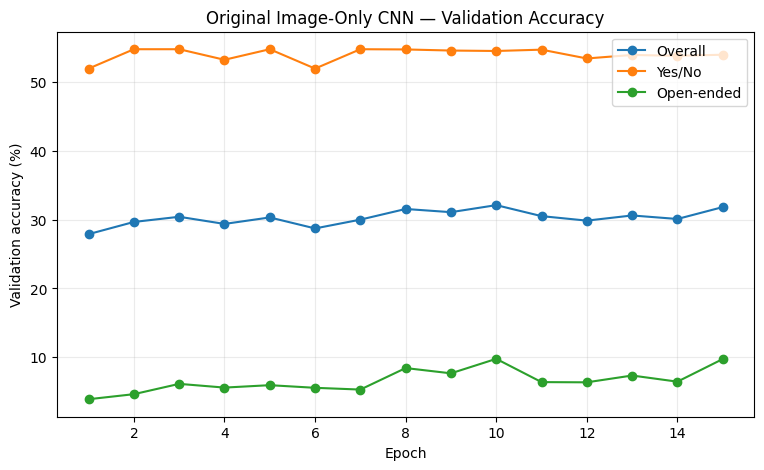

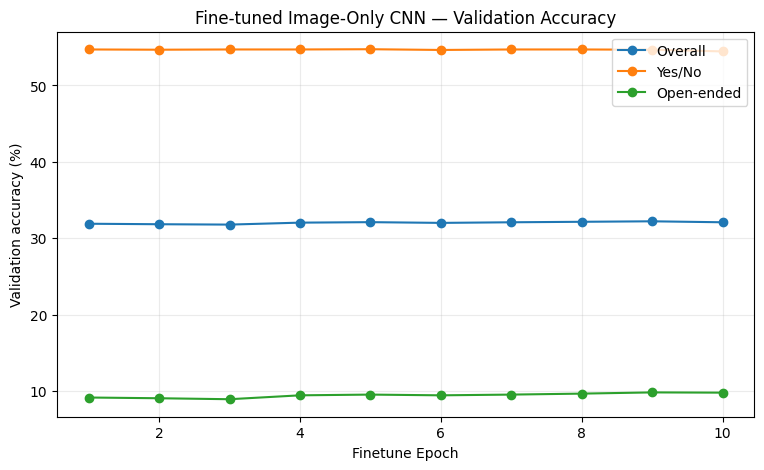

In [21]:
# Read saved histories and plot the original and fine-tuning phases.
def find_history(filename):
    paths = (
        glob.glob("/kaggle/working/" + filename)
        + glob.glob("/kaggle/input/**/" + filename, recursive=True)
    )
    return pd.read_csv(paths[0]) if paths else None

original_history_df = find_history("image_only_cnn_history.csv")
finetune_history_df = find_history("image_only_cnn_finetune_history.csv")

for title, df, xcol in [
    ("Original Image-Only CNN", original_history_df, "epoch"),
    ("Fine-tuned Image-Only CNN", finetune_history_df, "finetune_epoch")
]:
    if df is None:
        print("History unavailable:", title)
        continue
    plt.figure(figsize=(9, 5))
    for key, label in [
        ("overall_accuracy", "Overall"),
        ("yes_no_accuracy", "Yes/No"),
        ("open_accuracy", "Open-ended"),
    ]:
        plt.plot(df[xcol], 100 * df[key], marker="o", label=label)
    plt.title(title + " — Validation Accuracy")
    plt.xlabel(xcol.replace("_", " ").title())
    plt.ylabel("Validation accuracy (%)")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

## 17. Compare with previously completed baselines

The following numbers are **previously reported validation results**, not re-evaluated in this notebook. The two image-only rows come from the model you just evaluated.

All metrics use oracle answer-type routing and the same 1,000-answer vocabulary **except** the separately labeled CNN + BiLSTM 2K experiment. Do not compare the 2K experiment as a fully controlled 1K baseline.

In [22]:
# Display previously reported baseline validation scores for context, not as new test results.
comparison = pd.DataFrame([
    {"Model": "CNN + BiLSTM (original 1K)", "Overall (%)": 53.40, "Yes/No (%)": 85.86, "Open (%)": 21.03},
    {"Model": "CNN + BiLSTM (fine-tuned 1K)", "Overall (%)": 54.42, "Yes/No (%)": 86.43, "Open (%)": 22.50},
    {"Model": "Question-Only BiLSTM (original 1K)", "Overall (%)": 48.12, "Yes/No (%)": 85.02, "Open (%)": 11.33},
    {"Model": "Question-Only BiLSTM (fine-tuned 1K)", "Overall (%)": 48.20, "Yes/No (%)": 85.25, "Open (%)": 11.26},
    {"Model": "Image-Only CNN (original 1K)",
     "Overall (%)": 100 * original_metrics["overall_accuracy"],
     "Yes/No (%)": 100 * original_metrics["closed_accuracy"],
     "Open (%)": 100 * original_metrics["open_accuracy"]},
    {"Model": "Image-Only CNN (fine-tuned 1K)",
     "Overall (%)": 100 * finetuned_metrics["overall_accuracy"],
     "Yes/No (%)": 100 * finetuned_metrics["closed_accuracy"],
     "Open (%)": 100 * finetuned_metrics["open_accuracy"]},
])
display(comparison.round(2))
comparison.to_csv("/kaggle/working/image_only_full_comparison.csv", index=False)

,Model,Overall (%),Yes/No (%),Open (%)
0,CNN + BiLSTM (original 1K),53.40,85.86,21.03
1,CNN + BiLSTM (fine-tuned 1K),54.42,86.43,22.50
2,Question-Only BiLSTM (original 1K),48.12,85.02,11.33
3,Question-Only BiLSTM (fine-tuned 1K),48.20,85.25,11.26
4,Image-Only CNN (original 1K),32.11,54.53,9.76
5,Image-Only CNN (fine-tuned 1K),32.21,54.69,9.80


## 18. Checkpoint and history backup

Create a ZIP containing original/fine-tuned checkpoints and CSV results. Download the ZIP before the Kaggle session expires. A ZIP is created **only from named experiment files**, avoiding accidental inclusion of earlier ZIP archives.

In [23]:
# Package available checkpoints and history files for reproducibility and archiving.
filenames = [
    "best_image_only_cnn.pth",
    "image_only_cnn_latest.pth",
    "image_only_cnn_history.csv",
    "best_image_only_cnn_finetuned.pth",
    "image_only_cnn_finetune_latest.pth",
    "image_only_cnn_finetune_history.csv",
    "image_only_cnn_comparison.csv",
    "image_only_full_comparison.csv",
]
zip_path = "/kaggle/working/image_only_cnn_backup.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in filenames:
        path = "/kaggle/working/" + filename
        if os.path.isfile(path):
            zf.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Not available:", filename)
print("Backup ready:", zip_path)

Added: best_image_only_cnn.pth
Added: image_only_cnn_latest.pth
Added: image_only_cnn_history.csv
Added: best_image_only_cnn_finetuned.pth
Added: image_only_cnn_finetune_latest.pth
Added: image_only_cnn_finetune_history.csv
Added: image_only_cnn_comparison.csv
Added: image_only_full_comparison.csv
Backup ready: /kaggle/working/image_only_cnn_backup.zip
